# DNA Seesaw Circuit Simulations

This notebook demonstrates how to model DNA seesaw circuits (Figure 1) from the literature ([Thubagere et al., *Nat. Commun.* 2017](https://www.nature.com/articles/ncomms14373)) using exclusively the TMSE module. 

## Supplementary Figure Simulations:
* [Base Seesaw Reaction](#Base-Seesaw-Mchanism): Simulates the core seesaw mechanism where an Input and Gate react to produce an Output strand. This exposes a toehold that recruits a Fuel strand to displace the Input, freeing it to initiate another round of Output generation.
* Seesaw with Thresholding: Couples the seesaw reaction with a Threshold reaction.
    * [‘OR’ Gate](#Double-Gate,-Threshold-‘OR’-Gate): OR logic operations.
    * [‘AND’ Gate](#Double-Gate,-Threshold-‘AND’-Gate): AND logic operations. 

# Dependencies and packages

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from matplotlib.ticker import FormatStrFormatter
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

## Global variables and definitions

In [2]:
# Simulate all models - example for 6 hours
timepoints = np.linspace(0,6,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (hr)',fontsize=fs)
    plt.legend(title='Inputs',frameon=False, 
               title_fontsize = fs-4, fontsize=fs-4)

    plt.ylim(ymin,ymax)
    plt.xlim(0,6)
    plt.xticks(ticks=[0,1,2,3,4,5,6],fontsize=fs)
    plt.yticks(ticks=[0.0,0.2,0.4,0.6,0.8,1.0],fontsize=fs)
    
    # Setting the same number of decimal places for y-axis
    ax1 = plt.gca()
    ax1.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    
    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

# Base Seesaw Mechanism

In [3]:
# Define initial DNA and Reporter DNA
sim_inputs = {'I{2,}': ['Input',2],
              'G{2,4}':['Gate',2,4],
              'TG{2,}':['TGate',2],
              'F{2,f}':['Fuel',2,'f'],
              'R{4,}':['Reporter',4]} # DNA

# Components
step_sd = TMSE(sim_inputs)

# Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"kx":5e4/1e9,
                  "krev":5e4/1e9,
                  "krep":10e4/1e9,
                  "kth":2e6/1e9
                  } 

# Make Mixture and Compile
M_TMSE = Mixture("One_step_TMSE", 
                 components=[step_sd],
                 parameters = TMSE_parameters,
                 mechanisms=sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_TMSE = M_TMSE.compile_crn()

print(CRN_TMSE.pretty_print(show_rates = True, how_attributes = True, 
                            show_materials = True, show_keys = False))

Species(N = 12) = {
dna[Waste_2_2] (@ 0),  dna[Waste_2] (@ 0),  dna[TGate_2] (@ 0),  dna[Signal_4] (@ 0),  dna[Reporter_4] (@ 0),  dna[ReporterOut_4] (@ 0),  dna[Output_2_4] (@ 0),  dna[Input_2] (@ 0),  dna[Gate_2_4] (@ 0),  dna[GateOut_2_2] (@ 0),  dna[Fuel_2_f] (@ 0),  dna[FuelOut_2] (@ 0),  
}

Reactions (4) = [
0. dna[Gate_2_4]+dna[Input_2] <--> dna[Output_2_4]+dna[GateOut_2_2]
 Kf=k_forward * dna_Gate_2_4 * dna_Input_2
 Kr=k_reverse * dna_Output_2_4 * dna_GateOut_2_2
  k_forward=5e-05
  k_reverse=5e-05

1. dna[GateOut_2_2]+dna[Fuel_2_f] <--> dna[Input_2]+dna[FuelOut_2]
 Kf=k_forward * dna_GateOut_2_2 * dna_Fuel_2_f
 Kr=k_reverse * dna_Input_2 * dna_FuelOut_2
  k_forward=5e-05
  k_reverse=5e-05

2. dna[Input_2]+dna[TGate_2] --> dna[Waste_2]+dna[Waste_2_2]
 Kf=k_forward * dna_Input_2 * dna_TGate_2
  k_forward=0.002

3. dna[Output_2_4]+dna[Reporter_4] --> dna[Signal_4]+dna[ReporterOut_4]
 Kf=k_forward * dna_Output_2_4 * dna_Reporter_4
  k_forward=0.0001

]


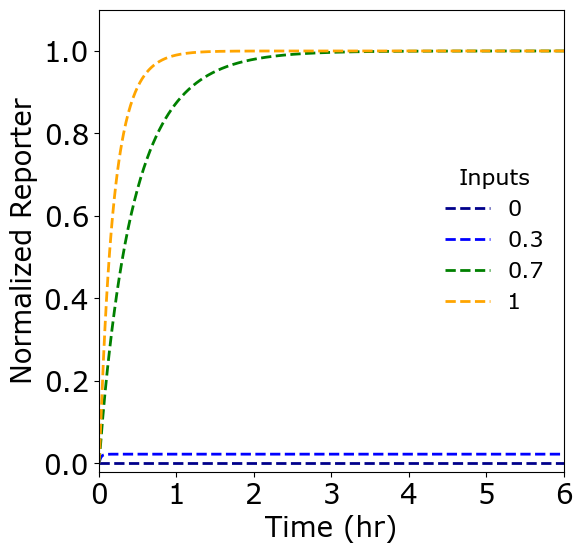

In [4]:
# Simulate
try:
    import numpy as np
    import pylab as plt
    
    # Simulating the model - example for 6 hours
    timepoints = np.linspace(0,10,1001)*3600 # Timepoints to simulate over

    # Input templates
    IN53_5 = [0, 0.3, 0.7, 1]
    colors =['darkblue','blue','green','orange']

    for IN_conc, color in zip(IN53_5, colors):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_2': IN_conc*100,'dna_Gate_2_4':100,
                                      'dna_Fuel_2_f':200,'dna_TGate_2':50,
                                      'dna_Reporter_4':150}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_TMSE.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                      initial_condition_dict = initial_concentration_dict)

        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_4']/100, label = str(IN_conc), 
                 color = color, linewidth = 2,linestyle='--')
        


except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Normalized Reporter',ymax = 1.1, fig_name= 'SeesawFig1')    


# Seesaw with Thresholding

## Double Gate, Threshold ‘OR’ Gate

*Note: The leak reaction is omitted from original reaction.*

In [5]:
# Define initial DNA and Reporter DNA
sim_inputs = {'O{5,1}': ['Output', 5,1], 'O{6,1}': ['Output', 6,1], # Inputs
              'G{1,2}':['Gate',1,2], 'G{2,4}':['Gate',2,4], # Gates
              'TG{2,}':['TGate',2], # Thresholds
              'F{2,}':['Fuel',2], # Fuels
              'R{4,}':['Reporter', 4]} # Reporters

# Components
step_strands =StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse =TMSE(step_strands.mol)

# Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"kx":5e4/1e9,
                  "krev":5e4/1e9,
                  "krep":10e4/1e9,
                  "kth":2e6/1e9
                  } 

# Make Mixture and Compile
M_TMSEor = Mixture("Threshold_OR", 
                   components=[step_tmse],
                   parameters = TMSE_parameters,
                   mechanisms=sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_TMSEor = M_TMSEor.compile_crn()

print(CRN_TMSEor.pretty_print(show_rates = True, show_attributes = True, 
                              show_materials = True, show_keys = False))

Species(N = 17) = {
dna[Waste_2] (@ 0),  dna[Waste_1_2] (@ 0),  dna[TGate_2] (@ 0),  dna[Signal_4] (@ 0),  dna[Reporter_4] (@ 0),  dna[ReporterOut_4] (@ 0),  dna[Output_6_1] (@ 0),  dna[Output_5_1] (@ 0),  dna[Output_2_4] (@ 0),  dna[Output_1_2] (@ 0),  dna[Gate_2_4] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_6_1] (@ 0),  dna[GateOut_5_1] (@ 0),  dna[GateOut_1_2] (@ 0),  dna[Fuel_2] (@ 0),  dna[FuelOut_2] (@ 0),  
}

Reactions (6) = [
0. dna[Gate_1_2]+dna[Output_5_1] <--> dna[Output_1_2]+dna[GateOut_5_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Output_5_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_5_1
  k_forward=5e-05
  k_reverse=5e-05

1. dna[Gate_1_2]+dna[Output_6_1] <--> dna[Output_1_2]+dna[GateOut_6_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Output_6_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_6_1
  k_forward=5e-05
  k_reverse=5e-05

2. dna[Gate_2_4]+dna[Output_1_2] <--> dna[Output_2_4]+dna[GateOut_1_2]
 Kf=k_forward * dna_Gate_2_4 * dna_Output_1_2
 Kr=k_reverse * dna_Output_2_4 * dna_Ga

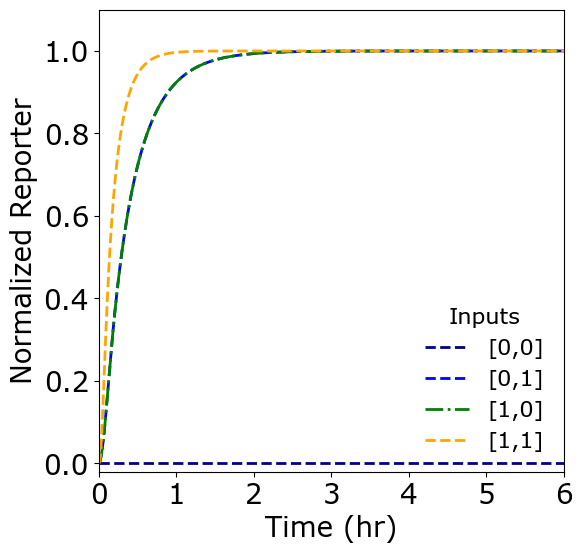

In [6]:
# Simulate
try:
    import pylab as plt

    # Input templates
    x1 = [0,0,1,1]
    x2 = [0,1,0,1]

    idx_conditions = {'None':['darkblue', '--'],
                      'I21': ['blue','--'],
                      'I27': ['green','-.'],
                      'I21&I27': ['orange','--']}

    for I21_conc, I27_conc, key in zip(x1, x2,idx_conditions.keys()):

        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Output_5_1': I21_conc*100, 'dna_Output_6_1': I27_conc*100,
                                      'dna_Gate_1_2':200, 'dna_Gate_2_4':100,
                                      'dna_TGate_2': 60,'dna_Fuel_2':200,
                                      'dna_Reporter_4':150}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_TMSEor.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                        initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_4']/100, label = f'[{I21_conc},{I27_conc}]',
                 color = idx_conditions[key][0], linewidth =2 ,linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Normalized Reporter',ymax = 1.1, fig_name= 'SeesawFig2')    

## Double Gate, Threshold ‘AND’ Gate

*Note: The leak reaction is omitted from original reaction.*


In [7]:
# Define initial DNA and Reporter DNA
sim_inputs = {'O{5,1}': ['Output', 5,1], 'O{6,1}': ['Output', 6,1], # Inputs
              'G{1,2}':['Gate',1,2], 'G{2,4}':['Gate',2,4], # Gates
              'TG{2,}':['TGate',2], # Thresholds
              'F{2,}':['Fuel',2], # Fuels
              'R{4,}':['Reporter', 4]} # Reporters
# Components
step_strands =StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse =TMSE(step_strands.mol)

#Reactions
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"kx":5e4/1e9,
                  "krev":5e4/1e9,
                  "krep":10e4/1e9,
                  "kth":2e6/1e9
                  } 

# Make Mixture and Compile
M_TMSand = Mixture("Threshold_AND", 
                   components=[step_tmse],
                   parameters = TMSE_parameters,
                   mechanisms=sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_TMSand = M_TMSand.compile_crn()

print(CRN_TMSand.pretty_print(show_rates = True, show_attributes = True, 
                              show_materials = True, show_keys = False))

Species(N = 17) = {
dna[Waste_2] (@ 0),  dna[Waste_1_2] (@ 0),  dna[TGate_2] (@ 0),  dna[Signal_4] (@ 0),  dna[Reporter_4] (@ 0),  dna[ReporterOut_4] (@ 0),  dna[Output_6_1] (@ 0),  dna[Output_5_1] (@ 0),  dna[Output_2_4] (@ 0),  dna[Output_1_2] (@ 0),  dna[Gate_2_4] (@ 0),  dna[Gate_1_2] (@ 0),  dna[GateOut_6_1] (@ 0),  dna[GateOut_5_1] (@ 0),  dna[GateOut_1_2] (@ 0),  dna[Fuel_2] (@ 0),  dna[FuelOut_2] (@ 0),  
}

Reactions (6) = [
0. dna[Gate_1_2]+dna[Output_5_1] <--> dna[Output_1_2]+dna[GateOut_5_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Output_5_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_5_1
  k_forward=5e-05
  k_reverse=5e-05

1. dna[Gate_1_2]+dna[Output_6_1] <--> dna[Output_1_2]+dna[GateOut_6_1]
 Kf=k_forward * dna_Gate_1_2 * dna_Output_6_1
 Kr=k_reverse * dna_Output_1_2 * dna_GateOut_6_1
  k_forward=5e-05
  k_reverse=5e-05

2. dna[Gate_2_4]+dna[Output_1_2] <--> dna[Output_2_4]+dna[GateOut_1_2]
 Kf=k_forward * dna_Gate_2_4 * dna_Output_1_2
 Kr=k_reverse * dna_Output_2_4 * dna_Ga

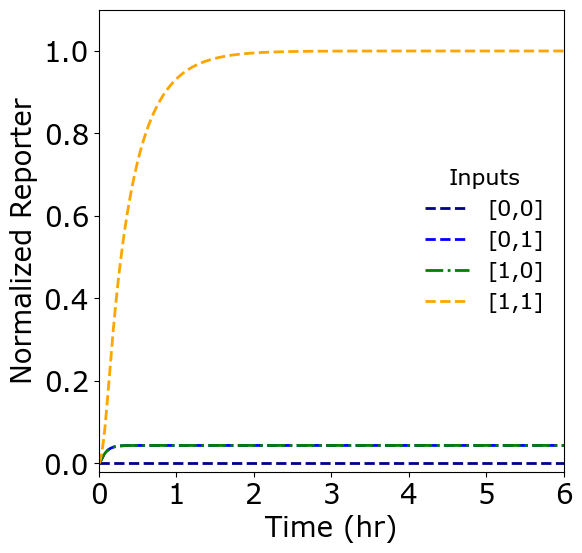

In [8]:
# Simulate
try:
    import pylab as plt

    # Input templates
    x1 = [0,0,1,1]
    x2 = [0,1,0,1]

    idx_conditions = {'None':['darkblue', '--'],
                      'I18': ['blue','--'],
                      'I22': ['green','-.'],
                      'I18&I22': ['orange','--']}

    for I18_conc, I22_conc, key in zip(x1, x2,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Output_5_1': I18_conc*100, 'dna_Output_6_1': I22_conc*100,
                                      'dna_Gate_1_2':200, 'dna_Gate_2_4':100,
                                      'dna_TGate_2': 120,'dna_Fuel_2':200,
                                      'dna_Reporter_4':150}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_TMSand.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                        initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_4']/100, label = f'[{I18_conc},{I22_conc}]',
                color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
        
except ModuleNotFoundError:
    print("Plotting Modules not installed.")


FormatPlot(ylabel='Normalized Reporter',ymax = 1.1, fig_name= 'SeesawFig3')    

# Computing environment

In [9]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

